# Search with Purged Validation

The protected training set for fold $j$ excludes every observation whose information interval touches the test interval or its embargo:

$$
T_j^{\mathrm{safe}}=\left\{i\notin F_j:I_i\cap\left(\bigcup_{q\in F_j}I_q\right)=\varnothing,\ i\notin E_j\right\}.
$$

Here, $F_j$ is test fold $j$, $I_i$ is the information interval for observation $i$, $E_j$ is the declared embargo region, and $T_j^{\mathrm{safe}}$ is the retained training set.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
from itertools import product
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
from IPython.display import Image
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib

DATA_URL = "https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip"
DATA_DIR = ROOT / "data" / "public" / "binance"
DATA_PATH = ensure_dataset(ROOT, "binance_btcusdt")
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
expected_data_hash = "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == expected_data_hash
public_columns = ["Open time", "Open", "High", "Low", "Close", "Volume", "Close time", "Quote volume", "Trades", "Buyer base volume", "Buyer quote volume", "Unused"]
raw = pd.read_csv(DATA_PATH, compression="zip", header=None, names=public_columns, nrows=None)
raw["time"] = pd.to_datetime(raw["Open time"], unit="ms", utc=True).dt.tz_convert(None)
raw = raw.rename(columns={"Close": "close", "Volume": "volume", "Quote volume": "quote_volume", "Trades": "trades"})
raw = raw.sort_values("time").drop_duplicates("time").reset_index(drop=True)

from RiskLabAI.backtest.validation import PurgedKFold
from RiskLabAI.optimization.hyper_parameter_tuning import SampleWeightedPipeline, clf_hyper_fit

FIGURES = ROOT / "outputs" / "figures" / "18_hyperparameter_selection"
TABLES = ROOT / "outputs" / "tables" / "18_hyperparameter_selection"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

minute_data = raw.set_index("time")
bars = pd.DataFrame({
    "Close": minute_data["close"].resample("15min").last(),
    "Volume": minute_data["volume"].resample("15min").sum(),
    "Quote volume": minute_data["quote_volume"].resample("15min").sum(),
    "Trades": minute_data["trades"].resample("15min").sum(),
}).dropna()
log_close = np.log(bars["Close"])
one_bar_return = log_close.diff()
expected_15 = bars["Close"].ewm(span=15, adjust=False).mean()
expected_55 = bars["Close"].ewm(span=55, adjust=False).mean()
feature_frame = pd.DataFrame({
    "Previous return": one_bar_return.shift(1),
    "Distance from EWM 15": (np.log(bars["Close"]) - np.log(expected_15)).shift(1),
    "Distance from EWM 55": (np.log(bars["Close"]) - np.log(expected_55)).shift(1),
    "One-hour return": log_close.diff(4).shift(1),
    "Past volatility": one_bar_return.shift(1).rolling(16).std(),
    "Log volume change": np.log1p(bars["Volume"]).diff().shift(1),
})
label_horizon = 8
forward_return = (log_close.shift(-label_horizon) - log_close).rename("Forward return")
direction = forward_return.gt(0).where(forward_return.notna()).astype("Int64").rename("Direction")
end_time = bars.index.to_series().shift(-label_horizon).rename("End time")
public_frame = pd.concat([feature_frame, direction, forward_return, end_time], axis=1).dropna()
public_x = public_frame[feature_frame.columns].astype(float)
public_y = public_frame["Direction"].astype(int)
public_forward_return = public_frame["Forward return"].astype(float)
event_times = public_frame["End time"]
absolute_return_weight = public_forward_return.abs()
sample_weight = (absolute_return_weight / absolute_return_weight.median()).clip(lower=0.25, upper=4.0)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def configuration_name(kernel, penalty):
    return f"{kernel.upper()}, C={penalty:g}"

def make_model(kernel, penalty):
    return Pipeline([
        ("scale", StandardScaler()),
        ("svc", SVC(kernel=kernel, C=float(penalty), gamma="scale")),
    ])

def fit_and_score(kernel, penalty, data, labels, train_indices, test_indices, weights=None):
    model = make_model(kernel, penalty)
    fit_arguments = {}
    if weights is not None:
        fit_arguments["svc__sample_weight"] = weights.iloc[train_indices].to_numpy()
    model.fit(data.iloc[train_indices], labels.iloc[train_indices], **fit_arguments)
    predictions = model.predict(data.iloc[test_indices])
    return {
        "F1": f1_score(labels.iloc[test_indices], predictions, zero_division=0),
        "Precision": precision_score(labels.iloc[test_indices], predictions, zero_division=0),
        "Recall": recall_score(labels.iloc[test_indices], predictions, zero_division=0),
    }

def purged_configuration_scores(data, labels, times, configurations, n_splits=5, embargo=0.01, weights=None):
    splitter = PurgedKFold(n_splits=n_splits, times=times, embargo=embargo)
    splits = list(splitter.split(data, labels))
    records = []
    for order, (kernel, penalty) in enumerate(configurations):
        fold_scores = []
        train_sizes = []
        removals = []
        for train_indices, test_indices in splits:
            values = fit_and_score(kernel, penalty, data, labels, train_indices, test_indices, weights)
            fold_scores.append(values["F1"])
            train_sizes.append(len(train_indices))
            removals.append(len(data) - len(test_indices) - len(train_indices))
        records.append({
            "Order": order,
            "Configuration": configuration_name(kernel, penalty),
            "Kernel": kernel,
            "C": float(penalty),
            "Mean F1": float(np.mean(fold_scores)),
            "F1 spread": float(np.std(fold_scores, ddof=1)),
            "Smallest fold F1": float(np.min(fold_scores)),
            "Largest fold F1": float(np.max(fold_scores)),
            "Mean training observations": float(np.mean(train_sizes)),
            "Mean removed observations": float(np.mean(removals)),
        })
    return pd.DataFrame(records)

def ordinary_configuration_scores(data, labels, times, configurations, n_splits=5, weights=None):
    splits = list(KFold(n_splits=n_splits, shuffle=False).split(data))
    records = []
    for order, (kernel, penalty) in enumerate(configurations):
        fold_scores = []
        for train_indices, test_indices in splits:
            fold_scores.append(fit_and_score(kernel, penalty, data, labels, train_indices, test_indices, weights)["F1"])
        records.append({
            "Order": order,
            "Configuration": configuration_name(kernel, penalty),
            "Kernel": kernel,
            "C": float(penalty),
            "Mean F1": float(np.mean(fold_scores)),
            "F1 spread": float(np.std(fold_scores, ddof=1)),
            "Smallest fold F1": float(np.min(fold_scores)),
            "Largest fold F1": float(np.max(fold_scores)),
        })
    return pd.DataFrame(records)

def selected_row(frame):
    ordered = frame.sort_values(["Mean F1", "Order"], ascending=[False, True])
    return ordered.iloc[0]

def residual_overlap_count(train_indices, test_indices, times):
    allowed = PurgedKFold.filtered_training_indices_with_embargo(times, times.iloc[test_indices], embargo_fraction=0, continous_test_times=True)
    allowed_positions = set(times.index.get_indexer(allowed.index).tolist())
    return sum(int(int(index) not in allowed_positions) for index in train_indices)
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Preliminary Search Reproduced

The score used by the released search for zero-one labels is the harmonic mean of precision and recall:

$$
F_1=\frac{2PR}{P+R},
\qquad
P=\frac{\mathrm{TP}}{\mathrm{TP}+\mathrm{FP}},
\qquad
R=\frac{\mathrm{TP}}{\mathrm{TP}+\mathrm{FN}}.
$$

Here, $P$ is precision, $R$ is recall, $\mathrm{TP}$ counts true positive predictions, $\mathrm{FP}$ counts false positive predictions, $\mathrm{FN}$ counts false negative predictions, and $F_1$ is the resulting selection score.

In [2]:
preliminary_grid = {"svc__kernel": ["linear", "rbf"], "svc__C": [1.0, 10.0]}
preliminary_configurations = [(kernel, penalty) for kernel, penalty in product(["linear", "rbf"], [1.0, 10.0])]
preliminary_pipeline = SampleWeightedPipeline([
    ("scale", StandardScaler()),
    ("svc", SVC(gamma="scale")),
])
preliminary_model = clf_hyper_fit(
    public_x,
    public_y,
    event_times,
    preliminary_pipeline,
    preliminary_grid,
    validator_type="purgedkfold",
    validator_params={"n_splits": 5, "embargo": 0.01},
    bagging=[0, 0.0, 1.0],
    rnd_search_iter=0,
    n_jobs=1,
    sample_weight=sample_weight.to_numpy(),
)
preliminary_surface = purged_configuration_scores(public_x, public_y, event_times, preliminary_configurations, n_splits=5, embargo=0.01, weights=sample_weight)
preliminary_best = selected_row(preliminary_surface)
preliminary_reproduction = pd.DataFrame({
    "Quantity": ["Observations", "EWM spans", "Kernels", "C values", "Protected folds", "Embargo fraction", "Released selected kernel", "Released selected C", "Manual selected kernel", "Manual selected C", "Manual best mean F1"],
    "Value": [len(public_x), "15 and 55", "linear and rbf", "1 and 10", 5, 0.01, preliminary_model.named_steps["svc"].kernel, preliminary_model.named_steps["svc"].C, preliminary_best["Kernel"], preliminary_best["C"], preliminary_best["Mean F1"]],
})
save_table(preliminary_surface, "preliminary_search_surface", "Protected scores for the four settings in the preliminary notebook search.", "tab:chapter16-preliminary-search-surface")
save_table(preliminary_reproduction, "preliminary_reproduction", "Reproduction and extension of the preliminary hyperparameter search.", "tab:chapter16-preliminary-reproduction", fit=False)
display(preliminary_surface)
display(preliminary_reproduction)

,Order,Configuration,Kernel,C,Mean F1,F1 spread,Smallest fold F1,Largest fold F1,Mean training observations,Mean removed observations
0,0,"LINEAR, C=1",linear,1,0.411903,0.276583,0.070845,0.657565,2324.8,36
1,1,"LINEAR, C=10",linear,10,0.411903,0.276583,0.070845,0.657565,2324.8,36
2,2,"RBF, C=1",rbf,1,0.469673,0.116103,0.283186,0.563553,2324.8,36
3,3,"RBF, C=10",rbf,10,0.519843,0.021268,0.482639,0.536050,2324.8,36


,Quantity,Value
0,Observations,2951
1,EWM spans,15 and 55
2,Kernels,linear and rbf
3,C values,1 and 10
4,Protected folds,5
5,Embargo fraction,0.01
6,Released selected kernel,rbf
7,Released selected C,10
8,Manual selected kernel,rbf
9,Manual selected C,10


## Comparing purged and ordinary selection surfaces

,Order,Configuration,Kernel,C,Mean F1,F1 spread,Smallest fold F1,Largest fold F1,Mean training observations,Mean removed observations
0,0,"LINEAR, C=0.01",linear,0.01,0.403342,0.287020,0.054945,0.657565,2324.8,36
1,1,"LINEAR, C=0.1",linear,0.10,0.412221,0.278483,0.070845,0.657565,2324.8,36
2,2,"LINEAR, C=1",linear,1,0.411903,0.276583,0.070845,0.657565,2324.8,36
3,3,"LINEAR, C=10",linear,10,0.411903,0.276583,0.070845,0.657565,2324.8,36
4,4,"LINEAR, C=100",linear,100,0.412074,0.276675,0.070845,0.657565,2324.8,36
5,5,"RBF, C=0.01",rbf,0.01,0.526116,0.294788,0,0.690344,2324.8,36
6,6,"RBF, C=0.1",rbf,0.10,0.425479,0.227207,0.113695,0.622485,2324.8,36
7,7,"RBF, C=1",rbf,1,0.469673,0.116103,0.283186,0.563553,2324.8,36
8,8,"RBF, C=10",rbf,10,0.519843,0.021268,0.482639,0.536050,2324.8,36
9,9,"RBF, C=100",rbf,100,0.514473,0.018559,0.488525,0.536332,2324.8,36


,Order,Configuration,Kernel,C,Mean F1,F1 spread,Smallest fold F1,Largest fold F1
0,0,"LINEAR, C=0.01",linear,0.01,0.409215,0.325614,0.033333,0.657565
1,1,"LINEAR, C=0.1",linear,0.10,0.417185,0.315060,0.044199,0.657565
2,2,"LINEAR, C=1",linear,1,0.402408,0.302447,0.044199,0.642117
3,3,"LINEAR, C=10",linear,10,0.401885,0.302177,0.044199,0.642117
4,4,"LINEAR, C=100",linear,100,0.401723,0.302057,0.044199,0.642117
5,5,"RBF, C=0.01",rbf,0.01,0.388047,0.354299,0,0.657565
6,6,"RBF, C=0.1",rbf,0.10,0.412285,0.247345,0.113402,0.609665
7,7,"RBF, C=1",rbf,1,0.497983,0.061951,0.428843,0.580741
8,8,"RBF, C=10",rbf,10,0.510915,0.030967,0.468085,0.541139
9,9,"RBF, C=100",rbf,100,0.510064,0.021178,0.481301,0.532872


,Fold,Test observations,Ordinary training observations,Protected training observations,Removed observations,Ordinary overlapping labels,Protected overlapping labels
0,1,591,2360,2323,37,8,0
1,2,590,2361,2316,45,16,0
2,3,590,2361,2316,45,16,0
3,4,590,2361,2316,45,16,0
4,5,590,2361,2353,8,8,0


,Validation rule,Selected kernel,Selected C,Selected mean F1,Selected F1 spread,Overlapping training labels
0,Ordinary ordered folds,rbf,10,0.510915,0.030967,64
1,Purged folds with embargo,rbf,0.01,0.526116,0.294788,0


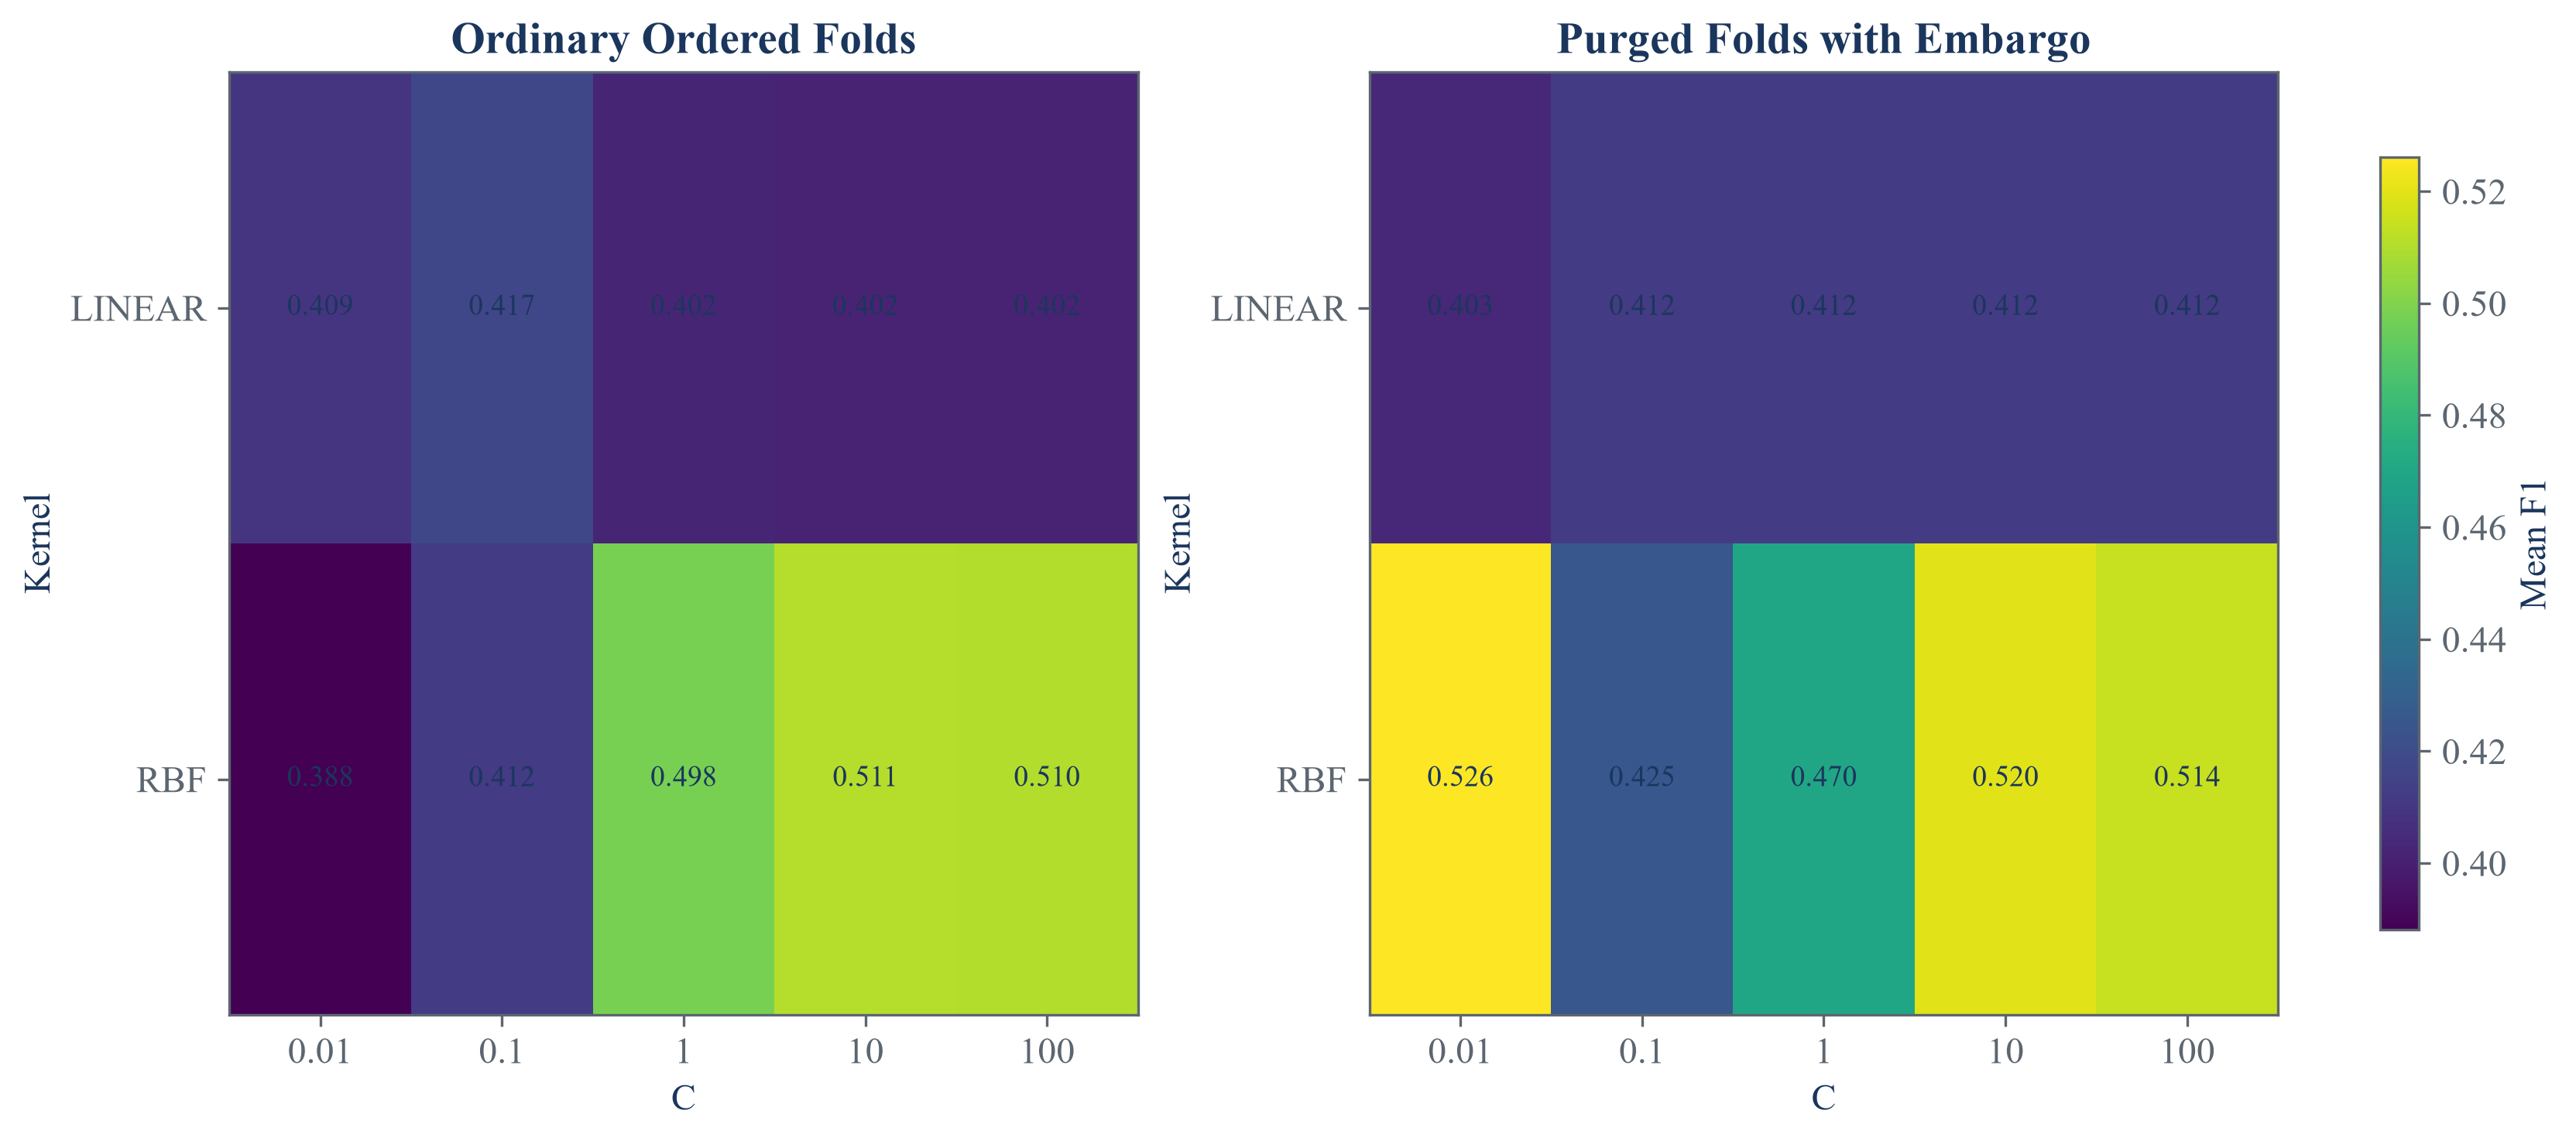

In [3]:
expanded_configurations = [(kernel, penalty) for kernel, penalty in product(["linear", "rbf"], [0.01, 0.1, 1.0, 10.0, 100.0])]
purged_score_surface = purged_configuration_scores(public_x, public_y, event_times, expanded_configurations, n_splits=5, embargo=0.01, weights=sample_weight)
ordinary_score_surface = ordinary_configuration_scores(public_x, public_y, event_times, expanded_configurations, n_splits=5, weights=sample_weight)
purged_best = selected_row(purged_score_surface)
ordinary_best = selected_row(ordinary_score_surface)

ordinary_splits = list(KFold(n_splits=5, shuffle=False).split(public_x))
protected_splits = list(PurgedKFold(n_splits=5, times=event_times, embargo=0.01).split(public_x, public_y))
protection_records = []
for fold, ((ordinary_train, ordinary_test), (protected_train, protected_test)) in enumerate(zip(ordinary_splits, protected_splits), start=1):
    protection_records.append({
        "Fold": fold,
        "Test observations": len(protected_test),
        "Ordinary training observations": len(ordinary_train),
        "Protected training observations": len(protected_train),
        "Removed observations": len(ordinary_train) - len(protected_train),
        "Ordinary overlapping labels": residual_overlap_count(ordinary_train, ordinary_test, event_times),
        "Protected overlapping labels": residual_overlap_count(protected_train, protected_test, event_times),
    })
fold_protection_summary = pd.DataFrame(protection_records)
search_comparison = pd.DataFrame({
    "Validation rule": ["Ordinary ordered folds", "Purged folds with embargo"],
    "Selected kernel": [ordinary_best["Kernel"], purged_best["Kernel"]],
    "Selected C": [ordinary_best["C"], purged_best["C"]],
    "Selected mean F1": [ordinary_best["Mean F1"], purged_best["Mean F1"]],
    "Selected F1 spread": [ordinary_best["F1 spread"], purged_best["F1 spread"]],
    "Overlapping training labels": [fold_protection_summary["Ordinary overlapping labels"].sum(), fold_protection_summary["Protected overlapping labels"].sum()],
})
save_table(purged_score_surface, "purged_score_surface", "Protected score surface over two kernels and five penalty values.", "tab:chapter16-purged-score-surface")
save_table(ordinary_score_surface, "ordinary_score_surface", "Ordinary ordered-fold score surface over the same candidate settings.", "tab:chapter16-ordinary-score-surface")
save_table(fold_protection_summary, "fold_protection_summary", "Training observations and overlapping labels under ordinary and protected folds.", "tab:chapter16-fold-protection-summary")
save_table(search_comparison, "search_comparison", "Selected settings under ordinary and protected validation.", "tab:chapter16-search-comparison")
display(purged_score_surface)
display(ordinary_score_surface)
display(fold_protection_summary)
display(search_comparison)

figure, axes = plt.subplots(1, 2, figsize=(11.0, 4.8), constrained_layout=True)
for axis, frame, title in zip(axes, [ordinary_score_surface, purged_score_surface], ["Ordinary Ordered Folds", "Purged Folds with Embargo"]):
    pivot = frame.pivot(index="Kernel", columns="C", values="Mean F1").reindex(index=["linear", "rbf"], columns=[0.01, 0.1, 1.0, 10.0, 100.0])
    image = axis.imshow(pivot.to_numpy(), aspect="auto", cmap="viridis", vmin=min(ordinary_score_surface["Mean F1"].min(), purged_score_surface["Mean F1"].min()), vmax=max(ordinary_score_surface["Mean F1"].max(), purged_score_surface["Mean F1"].max()))
    axis.set_title(title)
    axis.set_xlabel("C")
    axis.set_ylabel("Kernel")
    axis.set_xticks(np.arange(len(pivot.columns)))
    axis.set_xticklabels([f"{value:g}" for value in pivot.columns])
    axis.set_yticks(np.arange(len(pivot.index)))
    axis.set_yticklabels([value.upper() for value in pivot.index])
    for row in range(pivot.shape[0]):
        for column in range(pivot.shape[1]):
            axis.text(column, row, f"{pivot.iloc[row, column]:.3f}", ha="center", va="center", color=palette["text"], fontsize=9)
figure.colorbar(image, ax=axes, label="Mean F1", shrink=0.82)
figure.savefig(FIGURES / "ordinary_purged_score_surfaces.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "ordinary_purged_score_surfaces.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "ordinary_purged_score_surfaces.png")))
plt.close(figure)

The cumulative best score after evaluating the first $b$ settings is:

$$
B_b=\max_{1\leq r\leq b}\overline s(\theta_r).
$$

Here, $b$ is the number of evaluated settings, $r$ is their evaluation order, $\theta_r$ is the setting evaluated at step $r$, $\overline s(\theta_r)$ is its protected mean score, and $B_b$ is the best score found within that budget.

## Comparing three search strategies

,Released calculation,Selected kernel,Selected C,Candidate evaluations,Fitted members after selection
0,Exhaustive protected search,rbf,10,4,1
1,Three protected random draws,rbf,10,3,1
2,Bagged selected fit,rbf,10,1,5


,Evaluated settings,Grid-order best F1,Fixed-random-order best F1
0,1,0.403342,0.519843
1,2,0.412221,0.519843
2,3,0.412221,0.526116
3,4,0.412221,0.526116
4,5,0.412221,0.526116
5,6,0.526116,0.526116
6,7,0.526116,0.526116
7,8,0.526116,0.526116
8,9,0.526116,0.526116
9,10,0.526116,0.526116


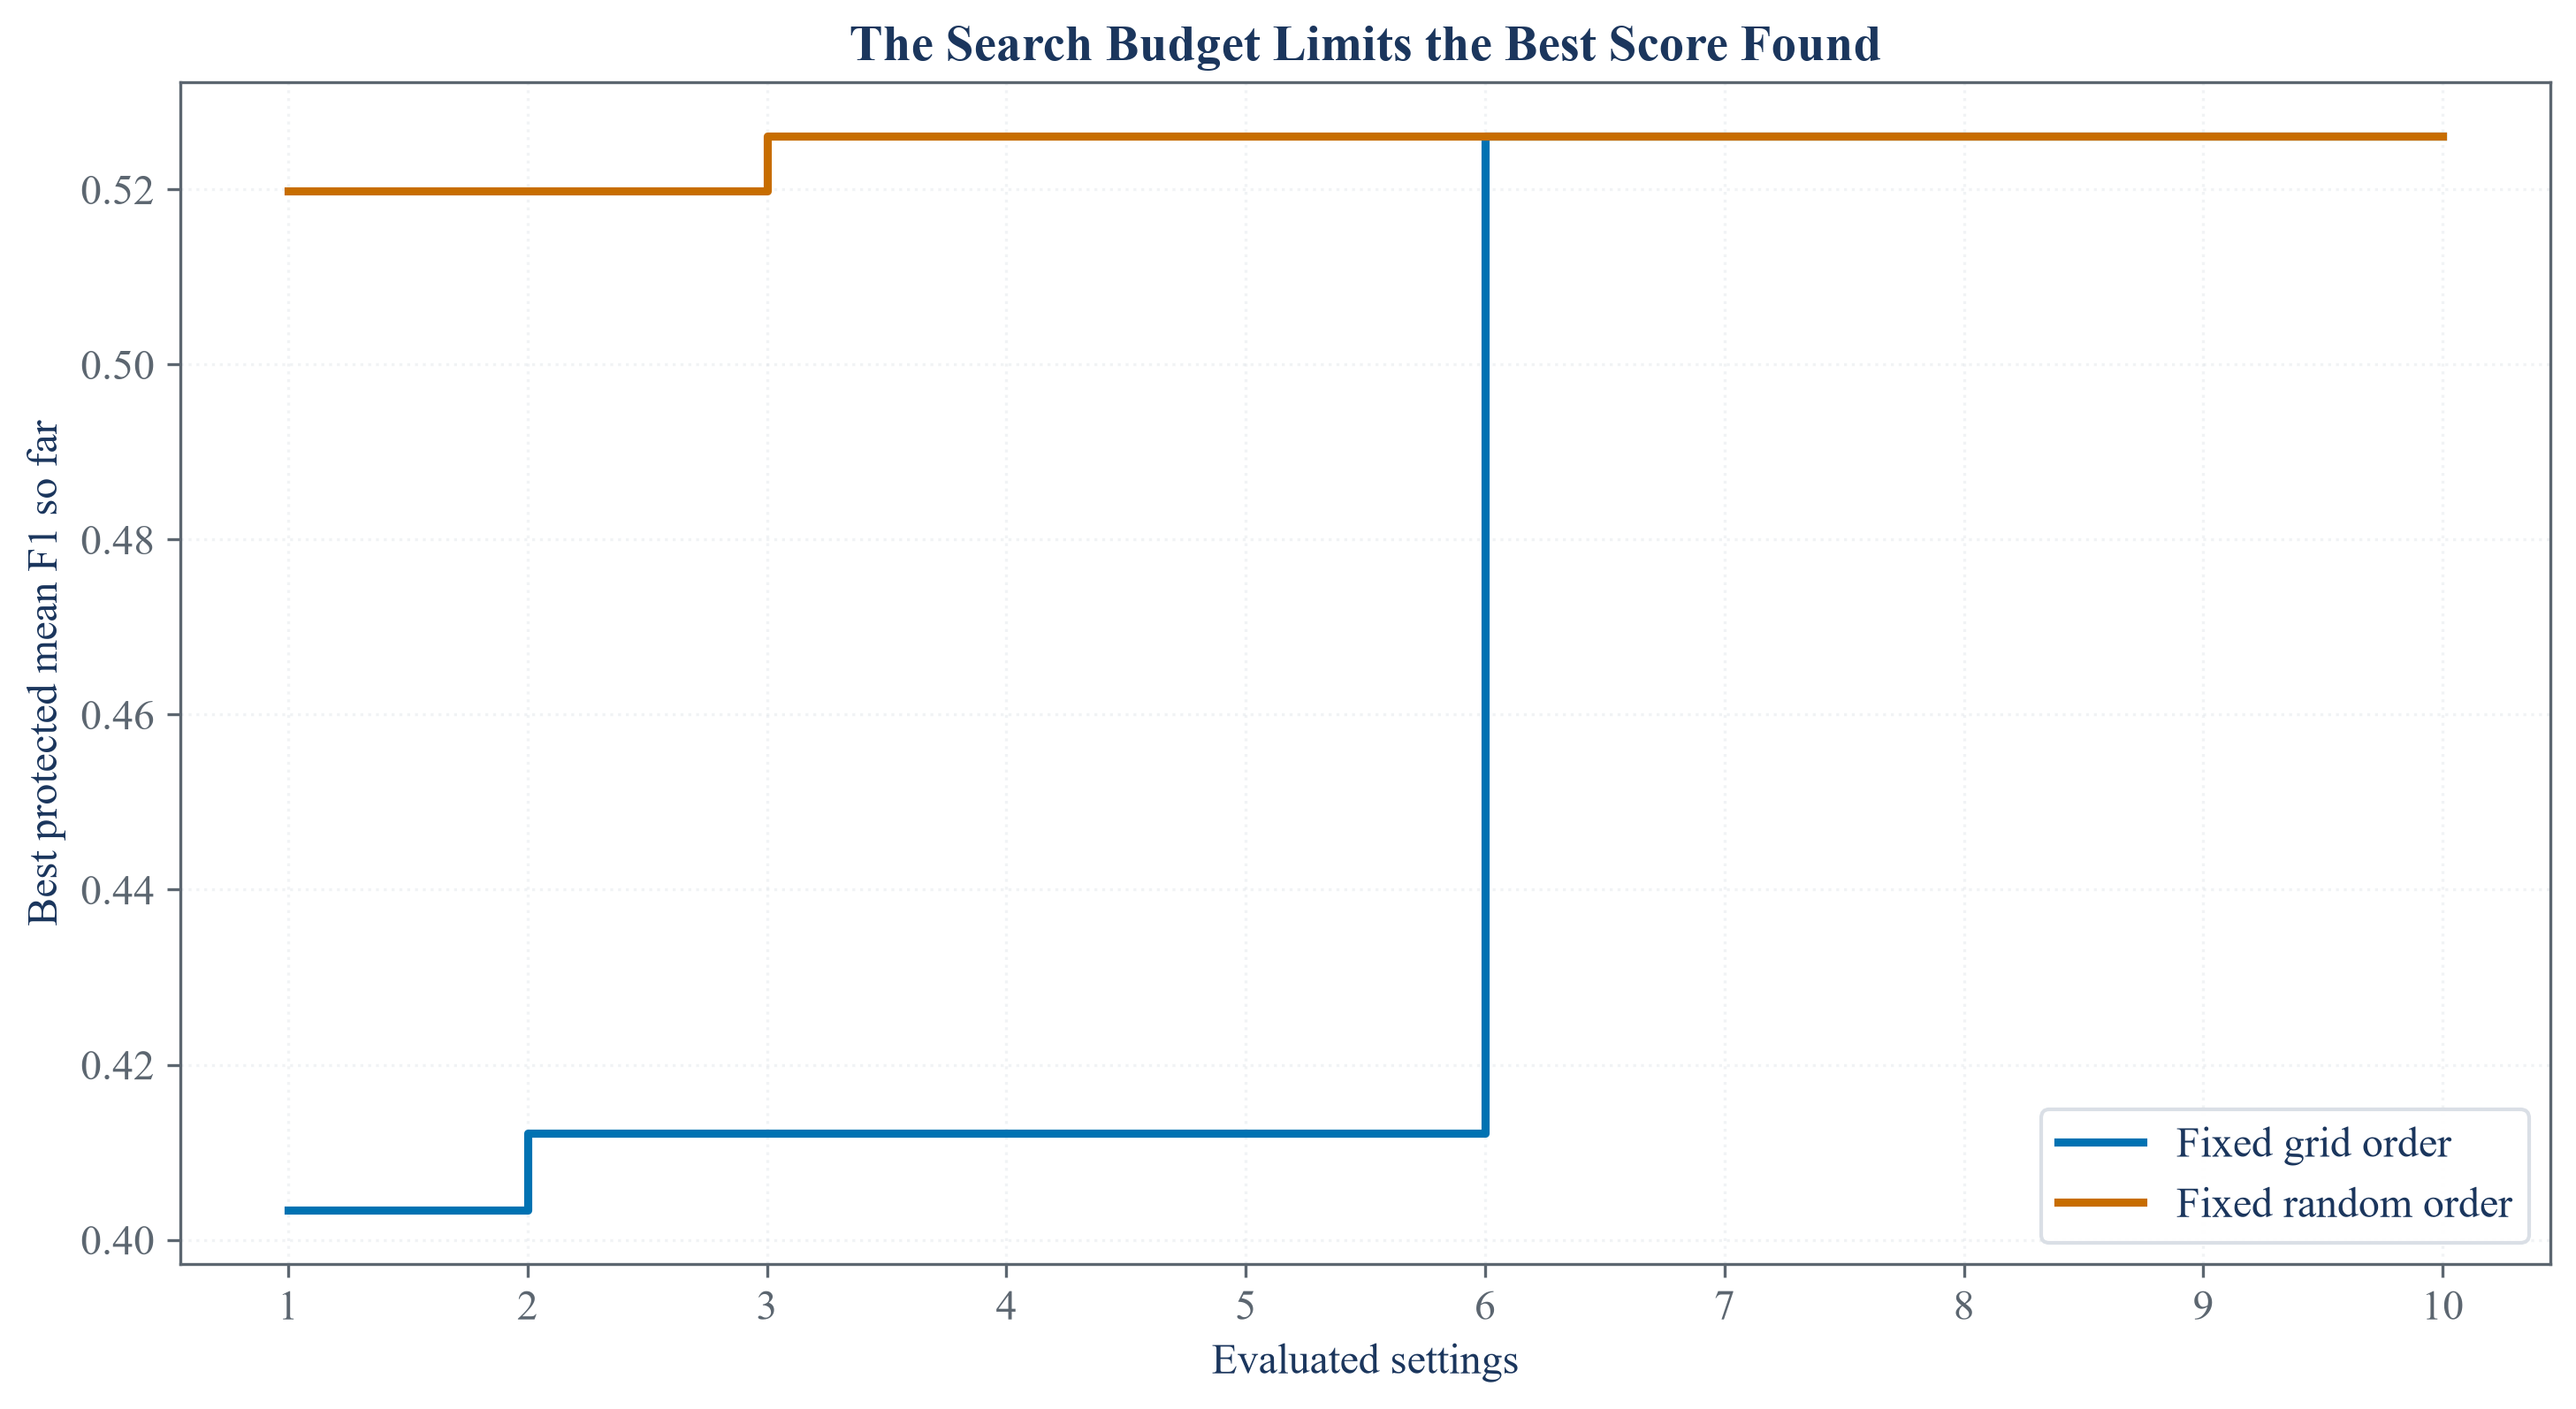

In [4]:
np.random.seed(16)
random_model = clf_hyper_fit(
    public_x,
    public_y,
    event_times,
    SampleWeightedPipeline([("scale", StandardScaler()), ("svc", SVC(gamma="scale"))]),
    preliminary_grid,
    validator_type="purgedkfold",
    validator_params={"n_splits": 5, "embargo": 0.01},
    bagging=[0, 0.0, 1.0],
    rnd_search_iter=3,
    n_jobs=1,
    sample_weight=sample_weight.to_numpy(),
)
np.random.seed(16)
bagged_model = clf_hyper_fit(
    public_x,
    public_y,
    event_times,
    SampleWeightedPipeline([("scale", StandardScaler()), ("svc", SVC(gamma="scale"))]),
    {"svc__kernel": [preliminary_best["Kernel"]], "svc__C": [preliminary_best["C"]]},
    validator_type="purgedkfold",
    validator_params={"n_splits": 5, "embargo": 0.01},
    bagging=[5, 0.8, 1.0],
    rnd_search_iter=0,
    n_jobs=1,
)
random_selected = random_model.named_steps["svc"]
bagged_step = bagged_model.named_steps["bag"]
bagged_selected = bagged_step.estimator.named_steps["svc"]
released_search_outputs = pd.DataFrame({
    "Released calculation": ["Exhaustive protected search", "Three protected random draws", "Bagged selected fit"],
    "Selected kernel": [preliminary_model.named_steps["svc"].kernel, random_selected.kernel, bagged_selected.kernel],
    "Selected C": [preliminary_model.named_steps["svc"].C, random_selected.C, bagged_selected.C],
    "Candidate evaluations": [4, 3, 1],
    "Fitted members after selection": [1, 1, bagged_step.n_estimators],
})
save_table(released_search_outputs, "released_search_outputs", "Outputs from the released exhaustive, random-draw, and bagged search paths.", "tab:chapter16-released-search-outputs")
display(released_search_outputs)

ordered_scores = purged_score_surface.sort_values("Order")["Mean F1"].to_numpy()
random_generator = np.random.default_rng(16)
random_order = random_generator.permutation(len(ordered_scores))
random_scores = ordered_scores[random_order]
search_budget_path = pd.DataFrame({
    "Evaluated settings": np.arange(1, len(ordered_scores) + 1),
    "Grid-order best F1": np.maximum.accumulate(ordered_scores),
    "Fixed-random-order best F1": np.maximum.accumulate(random_scores),
})
save_table(search_budget_path, "search_budget_path", "Best protected score reached as the search budget increases.", "tab:chapter16-search-budget-path", fit=False)
display(search_budget_path)

figure, axis = plt.subplots(figsize=(9.6, 5.2), constrained_layout=True)
axis.step(search_budget_path["Evaluated settings"], search_budget_path["Grid-order best F1"], where="post", linewidth=2.2, color=palette["cyan"], label="Fixed grid order")
axis.step(search_budget_path["Evaluated settings"], search_budget_path["Fixed-random-order best F1"], where="post", linewidth=2.2, color=palette["amber"], label="Fixed random order")
axis.set_title("The Search Budget Limits the Best Score Found")
axis.set_xlabel("Evaluated settings")
axis.set_ylabel("Best protected mean F1 so far")
axis.set_xticks(search_budget_path["Evaluated settings"])
axis.grid(alpha=0.35)
axis.legend()
figure.savefig(FIGURES / "search_budget_path.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "search_budget_path.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "search_budget_path.png")))
plt.close(figure)

## Tests

In [5]:
assert data_hash == "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
assert preliminary_surface.shape == (4, 10)
assert preliminary_reproduction.shape == (11, 2)
assert preliminary_model.named_steps["svc"].kernel in {"linear", "rbf"}
assert preliminary_model.named_steps["svc"].C in {1.0, 10.0}
assert preliminary_best["Kernel"] == preliminary_model.named_steps["svc"].kernel
assert preliminary_best["C"] == preliminary_model.named_steps["svc"].C
assert purged_score_surface.shape == (10, 10)
assert ordinary_score_surface.shape == (10, 8)
assert purged_score_surface["Mean F1"].between(0, 1).all()
assert ordinary_score_surface["Mean F1"].between(0, 1).all()
assert fold_protection_summary.shape == (5, 7)
assert fold_protection_summary["Removed observations"].gt(0).all()
assert fold_protection_summary["Ordinary overlapping labels"].gt(0).all()
assert fold_protection_summary["Protected overlapping labels"].eq(0).all()
assert search_comparison.shape == (2, 6)
assert random_selected.kernel in {"linear", "rbf"}
assert random_selected.C in {1.0, 10.0}
assert bagged_step.n_estimators == 5
assert bagged_selected.kernel == preliminary_best["Kernel"]
assert bagged_selected.C == preliminary_best["C"]
assert released_search_outputs.shape == (3, 5)
assert search_budget_path.shape == (10, 3)
assert search_budget_path["Grid-order best F1"].is_monotonic_increasing
assert search_budget_path["Fixed-random-order best F1"].is_monotonic_increasing
assert np.isclose(search_budget_path["Grid-order best F1"].iloc[-1], purged_score_surface["Mean F1"].max())
assert np.isclose(search_budget_path["Fixed-random-order best F1"].iloc[-1], purged_score_surface["Mean F1"].max())
assert (FIGURES / "ordinary_purged_score_surfaces.pdf").is_file()
assert (FIGURES / "search_budget_path.pdf").is_file()
assert (TABLES / "preliminary_search_surface.tex").is_file()
assert (TABLES / "preliminary_reproduction.tex").is_file()
assert (TABLES / "purged_score_surface.tex").is_file()
assert (TABLES / "ordinary_score_surface.tex").is_file()
assert (TABLES / "fold_protection_summary.tex").is_file()
assert (TABLES / "search_comparison.tex").is_file()
assert (TABLES / "released_search_outputs.tex").is_file()
assert (TABLES / "search_budget_path.tex").is_file()